# Graduate Admission: what drives a student's chance of admission?

**The question:** 500 applicants to graduate school have a GRE score, a TOEFL score, a rating of their target university, a statement-of-purpose (SOP) score, a recommendation-letter (LOR) score, an undergraduate GPA and a yes/no flag for research experience. Each also has a "chance of admission" between 0 and 1. Which of these things really matter, which ones are just echoing each other, and how well can a model predict the chance?

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data
4. Hypotheses and why we chose each test
5. H1: does research experience help? (a trap)
6. H2: which features matter?
7. H3: do two features add nothing?
8. H4: a leak-free model ladder
9. H5: which feature is "important"? Two ways to ask
10. Takeaways
11. Limitations

**Run it:** `uv run jupyter lab ML/graduate-admission/graduate_admission.ipynb`, or *Run All* in any Jupyter. **One manual step:** this dataset lives on Kaggle, which needs a free login, so download `Admission_Predict_Ver1.1.csv` from [Graduate Admissions](https://www.kaggle.com/datasets/mohansacharya/graduate-admissions) and save it as `data/Admission_Predict_Ver1.1.csv` next to this notebook. The loader below tells you the same thing if the file is missing.

## 1. 💡 The simple analogy

Imagine a **talent show with several judges** who all watch the same performance. The GRE judge, the TOEFL judge and the GPA judge mostly agree: a strong performer gets high marks from all three. So if we ask "which judge predicts who wins?", the answers get blurry, because the judges are **copying each other**.

Two ideas will carry this notebook:

- **Echoing features (collinearity):** when features are highly correlated, it's hard to say how much credit *each* deserves, and different methods split the credit differently.
- **The hidden helper (confounding):** students with research experience *also* tend to have higher GPAs and test scores. If we compare research and non-research students naively, we credit "research" with the effect of "being a strong student". We'll measure how much of the gap is really research.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed keeps the notebook reproducible and avoids "magic numbers". With the seed fixed, every bootstrap and cross-validation split comes out the same each time you run it.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy import stats
from scipy.special import expit, logit
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, RepeatedKFold, cross_val_predict, cross_validate
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.outliers_influence import variance_inflation_factor

DATA_PATH = Path("data/Admission_Predict_Ver1.1.csv")
OUT_DIR = Path("outputs")
SEED = 42
N_BOOTSTRAP = 5_000
CV_SPLITS, CV_REPEATS = 5, 10
TEAL, ORANGE, NAVY, GREY = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if p < 1e-300 else f"{p:.1e}"

## 3. Audit the data first

*What:* load the file and check what each column means and whether it is clean. *Why:* the legacy notebook never questioned the data. Three things to look for here: sloppy column names (the raw file has trailing spaces, like `'LOR '` and `'Chance of Admit '`, that cause confusing errors later), an index column (`Serial No.`) that is not a feature, and the nature of the *target*.

> **What is "Chance of Admit"?** It is a **number between 0 and 1 attached to each applicant**, not a record of whether they were actually accepted. The dataset was built for teaching (it is "inspired by" real graduate-admission data), so the target is best read as an *estimated* chance, and any model learns whatever process produced those numbers. We'll keep that in mind when we interpret results.

In [2]:
def load_admissions(path: Path = DATA_PATH) -> pd.DataFrame:
    """Loads the graduate admissions data and tidies the column names.

    Args:
        path: Location of ``Admission_Predict_Ver1.1.csv``.

    Returns:
        DataFrame with seven features and a ``Chance of Admit`` target (500 rows).

    Raises:
        FileNotFoundError: If the file has not been downloaded (it needs a Kaggle login).
        ValueError: If the data is not the expected shape or contains nulls.
    """
    if not path.exists():
        raise FileNotFoundError(
            f"{path} not found. Download 'Admission_Predict_Ver1.1.csv' from "
            "https://www.kaggle.com/datasets/mohansacharya/graduate-admissions "
            "(free Kaggle login) and save it there."
        )
    table = pd.read_csv(path)
    table.columns = [name.strip() for name in table.columns]  # 'LOR ' -> 'LOR'
    table = table.drop(columns="Serial No.")
    if table.shape != (500, 8) or table.isna().any().any():
        raise ValueError(f"Unexpected data: shape={table.shape}")
    return table


df = load_admissions()
TARGET = "Chance of Admit"
FEATURES = [c for c in df.columns if c != TARGET]
X, y = df[FEATURES], df[TARGET]
print(
    f"Applicants: {len(df)}   Features: {len(FEATURES)}   Missing values: "
    f"{int(df.isna().sum().sum())}   Duplicate rows: {df.duplicated().sum()}"
)
print(f"Research experience: {int(df['Research'].sum())} yes, {int((1 - df['Research']).sum())} no")
df.describe().round(2).T

Applicants: 500   Features: 7   Missing values: 0   Duplicate rows: 0
Research experience: 280 yes, 220 no


,count,mean,std,min,25%,50%,75%,max
GRE Score,500.0,316.47,11.30,290.00,308.00,317.00,325.00,340.00
TOEFL Score,500.0,107.19,6.08,92.00,103.00,107.00,112.00,120.00
University Rating,500.0,3.11,1.14,1.00,2.00,3.00,4.00,5.00
SOP,500.0,3.37,0.99,1.00,2.50,3.50,4.00,5.00
LOR,500.0,3.48,0.93,1.00,3.00,3.50,4.00,5.00
CGPA,500.0,8.58,0.60,6.80,8.13,8.56,9.04,9.92
Research,500.0,0.56,0.50,0.00,0.00,1.00,1.00,1.00
Chance of Admit,500.0,0.72,0.14,0.34,0.63,0.72,0.82,0.97


**How to read this.** There are **500 applicants**, no missing values and no duplicates, and every column sits in a believable range: GRE 290 to 340, TOEFL 92 to 120, GPA (CGPA, on a 10-point scale) 6.8 to 9.9, the SOP and LOR ratings 1 to 5, and the university rating 1 to 5. **56%** of applicants (280) have research experience. The chance of admission averages **0.72**, ranging from 0.34 to 0.97.

## 4. 🔬 Hypotheses and why we chose each test

Here are the questions, each with its null (H₀, "nothing special") and alternative (Hₐ), written **before** looking at any p-values:

| # | Question | H₀ | Hₐ | Method |
|---|---|---|---|---|
| H1 | Do applicants with research experience have a different chance of admission? And is that gap really *due to* research? | No difference (raw); no research effect once other features are held fixed (adjusted) | A difference exists | Mann-Whitney U, Cliff's δ and a bootstrap CI for the raw gap; OLS with robust standard errors for the adjusted effect |
| H2 | Does each feature move with the chance of admission? | Spearman ρ = 0 | ρ ≠ 0 | Spearman with Holm correction; VIF for overlap between features |
| H3 | Do University Rating and SOP add anything once the other five features are known? | Their coefficients are both 0 | At least one is not | Partial F-test between nested regressions |
| H4 | Does a more flexible model beat a simple linear one? | MAE difference = 0 | A complex model has lower error | Leak-free repeated CV with paired Nadeau-Bengio tests |
| H5 | Do different "importance" methods agree on which feature matters? | (descriptive) | They disagree when features echo each other | Impurity importance vs permutation importance on held-out data |

**Why Mann-Whitney U and Cliff's δ?** Mann-Whitney U lines every applicant up from lowest to highest chance and asks whether one group tends to sit higher. It doesn't assume a bell shape. **Cliff's δ** says *how big* the difference is: pick one applicant from each group at random; δ is *P(group A has the higher chance) − P(group A has the lower chance)*, from −1 to +1 (|δ| about 0.15 small, 0.33 medium, 0.47 large).

**Why robust (HC3) standard errors?** Ordinary regression assumes the scatter around the line is the same everywhere. We'll see that isn't true near the top of the 0 to 1 scale, so we use **heteroscedasticity-robust (HC3)** standard errors, which stay trustworthy when the scatter varies.

**Why Holm correction?** We test several features at once; do enough tests and one looks "significant" by luck, like buying more lottery tickets. Holm adjusts the p-values so the chance of *any* false alarm across the whole family stays at 5%.

## 5. H1: does research experience help? (a trap)

### The raw comparison

*What:* compare the chance of admission for applicants with and without research experience. *How:* Mann-Whitney U with Cliff's δ, plus a **bootstrap 95% CI** for the difference in medians (re-draw each group with replacement 5,000 times). We also run a Welch t-test (compares averages without assuming equal spread) to confirm the conclusion doesn't depend on the test.

In [3]:
def bootstrap_median_diff(
    a: np.ndarray, b: np.ndarray, rng: np.random.Generator
) -> tuple[float, float, float]:
    """Bootstraps a 95% CI for the difference in medians (a minus b).

    Args:
        a: Values in group A.
        b: Values in group B.
        rng: Random generator, so the result is reproducible.

    Returns:
        Observed difference, CI lower bound, CI upper bound.
    """
    boot_a = np.median(rng.choice(a, (N_BOOTSTRAP, len(a))), axis=1)
    boot_b = np.median(rng.choice(b, (N_BOOTSTRAP, len(b))), axis=1)
    lo, hi = np.percentile(boot_a - boot_b, [2.5, 97.5])
    return float(np.median(a) - np.median(b)), float(lo), float(hi)


rng = np.random.default_rng(SEED)
with_research = y[df["Research"] == 1].to_numpy()
without_research = y[df["Research"] == 0].to_numpy()
mwu = stats.mannwhitneyu(with_research, without_research)
delta = 2 * mwu.statistic / (len(with_research) * len(without_research)) - 1
welch = stats.ttest_ind(with_research, without_research, equal_var=False)
gap, gap_lo, gap_hi = bootstrap_median_diff(with_research, without_research, rng)

print(
    f"Median chance: {np.median(with_research):.3f} with research vs "
    f"{np.median(without_research):.3f} without"
)
print(f"Median difference: {gap:+.3f} (95% bootstrap CI {gap_lo:+.3f} to {gap_hi:+.3f})")
print(
    f"Mann-Whitney p = {fmt_p(mwu.pvalue)}, Cliff's delta = {delta:+.2f}; "
    f"Welch t-test p = {fmt_p(welch.pvalue)}"
)

Median chance: 0.800 with research vs 0.645 without
Median difference: +0.155 (95% bootstrap CI +0.130 to +0.180)
Mann-Whitney p = 1.3e-36, Cliff's delta = +0.66; Welch t-test p = 8.7e-41


**How to read this.** Applicants with research experience have a median chance of **0.80**, against **0.645** without: a raw gap of about **+0.155 (15.5 percentage points)**, with a bootstrap CI that is tight around it. Mann-Whitney (p ≈ 1e-36) and Welch (p ≈ 9e-41) agree, and Cliff's δ ≈ **+0.66** is a **large** effect. So **we reject H₀ for the raw comparison**.

**But wait.** Before crediting research with a 15-point boost, ask: *are the research students otherwise similar?* The talent-show lesson says to check whether the "judges" are echoing a hidden helper. Let's see how the two groups differ in their grades and test scores.

In [4]:
compare = df.groupby("Research")[["CGPA", "GRE Score", "TOEFL Score", "LOR"]].mean().round(2)
compare.index = ["No research", "Research"]
display(compare)

cgpa_mwu = stats.mannwhitneyu(
    df.loc[df["Research"] == 1, "CGPA"], df.loc[df["Research"] == 0, "CGPA"]
)
cgpa_delta = 2 * cgpa_mwu.statistic / (len(with_research) * len(without_research)) - 1
print(
    f"CGPA, research vs no research: Mann-Whitney p = {fmt_p(cgpa_mwu.pvalue)}, "
    f"Cliff's delta = {cgpa_delta:+.2f}"
)

,CGPA,GRE Score,TOEFL Score,LOR
No research,8.23,309.30,103.99,3.10
Research,8.84,322.11,109.71,3.79


CGPA, research vs no research: Mann-Whitney p = 5.5e-30, Cliff's delta = +0.59


**How to read this.** Students with research experience have a higher average **CGPA (8.84 against 8.23)**, a higher **GRE (322 against 309)** and higher TOEFL and LOR scores. The CGPA gap alone is a large effect (Cliff's δ ≈ +0.59). So the research group is a *stronger group of students overall*, and part of the 15-point gap is simply "strong students tend to have done research".

### The adjusted comparison

*What:* fit one **multiple regression** of the chance of admission on **all seven features together**. Each coefficient then answers: *among applicants with the same GPA, GRE, TOEFL, ratings and so on, how much more is the chance for someone with research?* We standardise the six numeric features (so a coefficient reads as "change in chance per 1 standard deviation") and leave `Research` as a 0/1 flag. We use HC3 robust standard errors and report 95% CIs. **H₀:** the research coefficient is 0.

In [5]:
def adjusted_effects(features: pd.DataFrame, target: pd.Series) -> tuple[pd.DataFrame, object]:
    """Fits OLS with robust (HC3) standard errors on standardised numeric features.

    Args:
        features: Feature table; ``Research`` is kept as a 0/1 flag.
        target: Chance of admission.

    Returns:
        A table of coefficients with 95% CIs and p-values, and the fitted model.
    """
    numeric = [c for c in features.columns if c != "Research"]
    scaled = features.copy()
    scaled[numeric] = (features[numeric] - features[numeric].mean()) / features[numeric].std()
    model = sm.OLS(target, sm.add_constant(scaled)).fit(cov_type="HC3")
    ci = model.conf_int()
    table = pd.DataFrame(
        {"effect": model.params, "ci_low": ci[0], "ci_high": ci[1], "p": model.pvalues}
    ).drop(index="const")
    return table, model


effects, full_model = adjusted_effects(X, y)
effects = effects.sort_values("effect", ascending=False)
research = effects.loc["Research"]
print(f"Model R-squared = {full_model.rsquared:.3f} (adjusted {full_model.rsquared_adj:.3f})")
print(
    f"Research, adjusted: {research['effect']:+.3f} (95% CI {research['ci_low']:+.3f} to "
    f"{research['ci_high']:+.3f}), p = {fmt_p(research['p'])}"
)
print(
    f"Raw gap {gap:+.3f} -> adjusted {research['effect']:+.3f}: "
    f"about {1 - research['effect'] / gap:.0%} of the raw gap disappears"
)
effects.style.format(
    {"effect": "{:+.4f}", "ci_low": "{:+.4f}", "ci_high": "{:+.4f}", "p": "{:.4f}"}
)

Model R-squared = 0.822 (adjusted 0.819)
Research, adjusted: +0.024 (95% CI +0.009 to +0.040), p = 1.9e-03
Raw gap +0.155 -> adjusted +0.024: about 84% of the raw gap disappears


,effect,ci_low,ci_high,p
CGPA,+0.0716,+0.0599,+0.0833,0.0000
Research,+0.0243,+0.0090,+0.0397,0.0019
GRE Score,+0.0210,+0.0090,+0.0330,0.0006
TOEFL Score,+0.0169,+0.0078,+0.0260,0.0003
LOR,+0.0156,+0.0087,+0.0225,0.0000
University Rating,+0.0068,-0.0018,+0.0154,0.1224
SOP,+0.0016,-0.0089,+0.0120,0.7687


### How the gap shrinks, step by step

*What:* the same research coefficient, but controlling for progressively more: first **only GPA**, then **everything**. *Why:* it shows how much of the raw gap is explained by GPA alone and how much by the other scores.

In [6]:
def research_effect(controls: list[str]) -> tuple[float, float, float]:
    """Research coefficient (robust CI) after holding the ``controls`` fixed.

    Args:
        controls: Features to hold fixed, besides ``Research`` itself.

    Returns:
        Coefficient, CI lower bound, CI upper bound.
    """
    model = sm.OLS(y, sm.add_constant(df[[*controls, "Research"]])).fit(cov_type="HC3")
    low, high = model.conf_int().loc["Research"]
    return float(model.params["Research"]), float(low), float(high)


steps = pd.DataFrame(
    {
        "Raw gap (medians)": (gap, gap_lo, gap_hi),
        "Holding GPA fixed": research_effect(["CGPA"]),
        "Holding all other features fixed": research_effect(
            [c for c in FEATURES if c != "Research"]
        ),
    },
    index=["effect", "ci_low", "ci_high"],
).T
steps["share of raw gap left"] = steps["effect"] / gap
steps.style.format(
    {
        "effect": "{:+.3f}",
        "ci_low": "{:+.3f}",
        "ci_high": "{:+.3f}",
        "share of raw gap left": "{:.0%}",
    }
)

,effect,ci_low,ci_high,share of raw gap left
Raw gap (medians),+0.155,+0.130,+0.180,100%
Holding GPA fixed,+0.039,+0.025,+0.054,25%
Holding all other features fixed,+0.024,+0.009,+0.040,16%


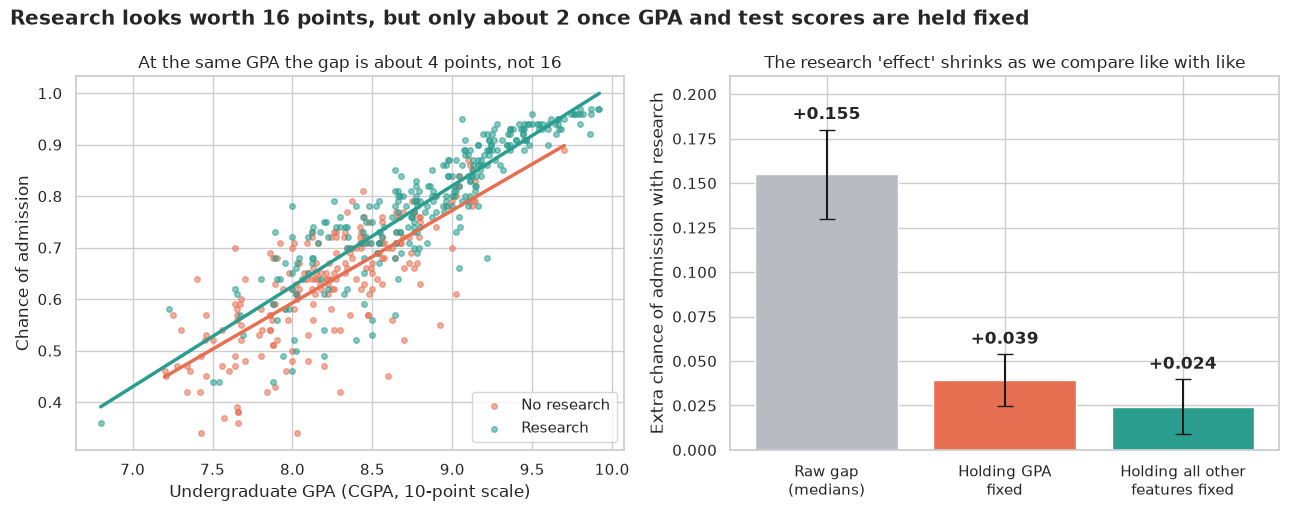

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
palette = {0: ORANGE, 1: TEAL}
gpa_gap = steps.loc["Holding GPA fixed", "effect"]
for flag, name in ((0, "No research"), (1, "Research")):
    part = df[df["Research"] == flag]
    axes[0].scatter(part["CGPA"], part[TARGET], s=16, alpha=0.55, color=palette[flag], label=name)
    slope, intercept = np.polyfit(part["CGPA"], part[TARGET], 1)
    xs = np.linspace(part["CGPA"].min(), part["CGPA"].max(), 50)
    axes[0].plot(xs, intercept + slope * xs, color=palette[flag], lw=2.5)
axes[0].set_xlabel("Undergraduate GPA (CGPA, 10-point scale)")
axes[0].set_ylabel("Chance of admission")
axes[0].legend(loc="lower right")
axes[0].set_title(
    f"At the same GPA the gap is about {gpa_gap * 100:.0f} points, not {gap * 100:.0f}"
)

labels = ["Raw gap\n(medians)", "Holding GPA\nfixed", "Holding all other\nfeatures fixed"]
values = steps["effect"].to_numpy()
errs = [values - steps["ci_low"].to_numpy(), steps["ci_high"].to_numpy() - values]
axes[1].bar(labels, values, yerr=errs, color=[GREY, ORANGE, TEAL], capsize=6)
for i, (value, top) in enumerate(zip(values, steps["ci_high"], strict=True)):
    axes[1].text(i, top + 0.006, f"{value:+.3f}", ha="center", fontweight="bold")
axes[1].set_ylabel("Extra chance of admission with research")
axes[1].set_ylim(0, 0.21)
axes[1].set_title("The research 'effect' shrinks as we compare like with like")
fig.suptitle(
    f"Research looks worth {gap * 100:.0f} points, but only about "
    f"{values[-1] * 100:.0f} once GPA and test scores are held fixed",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_research_confounding.png", dpi=150)
plt.show()

**How to read this.**

- **Adjusted research effect: about +0.024** (2.4 percentage points), with a 95% CI of roughly +0.009 to +0.040 and p ≈ 0.002. **We still reject H₀: research experience does matter, but its real effect is small.** About **84%** of the raw 15.5-point gap **disappears** once we account for the research students' stronger GPAs and test scores.
- **GPA alone does most of the work.** The step-by-step table and the right-hand chart show the raw +0.155 gap shrinking to **+0.039 (CI +0.025 to +0.054) once GPA is held fixed**, so GPA accounts for about **75%** of the gap. Holding *all* the other scores fixed as well takes it to **+0.024**, leaving only about 16% of the raw gap.
- The left plot shows the GPA step. Each dot is an applicant, and the orange (no research) and teal (research) fitted lines are only about **4 points apart at the same GPA**, instead of the 15.5 points the raw medians suggest. The big raw gap arises because research applicants are concentrated at the right-hand side (higher GPAs), where everybody has a higher chance.
- This is **confounding**: a third factor (overall strength) drives both research experience and admission chance. A naive comparison tells you the *raw association*; a regression that holds other features fixed gets closer to the *specific* contribution. (It is still an association, not proof of cause: unmeasured things could also be at work.)
- **Full adjusted table:** `CGPA` dominates (+0.072 per standard deviation, CI about +0.060 to +0.083), followed by `GRE` (+0.021), `TOEFL` (+0.017) and `LOR` (+0.016), with `Research` (+0.024). **University rating (+0.007, CI crossing 0) and `SOP` (+0.002, CI crossing 0) are not distinguishable from zero.** The model explains about **82%** of the variation (R² ≈ 0.82).

## 6. H2: which features matter?

### Each feature on its own (Spearman)

*What:* the Spearman rank correlation of each feature with the chance of admission, Holm-corrected. *Why Spearman?* It works on the *order* of the values, so it ignores outliers and catches any "goes up together" trend. ρ runs from −1 to +1 (0 = no link; 0.3 moderate, 0.5 strong, 0.7+ very strong).

### How much do the features echo each other? (VIF)

*What:* the **variance inflation factor (VIF)** says how much a coefficient's uncertainty is inflated by overlap with the other features. Below 5 is fine; above 10 is a serious problem.

In [8]:
spearman = pd.DataFrame({f: stats.spearmanr(X[f], y) for f in FEATURES}, index=["rho", "p"]).T
spearman["p_holm"] = multipletests(spearman["p"], method="holm")[1]
spearman = spearman.sort_values("rho", ascending=False)

design = sm.add_constant(X)
vif = pd.Series(
    {
        name: variance_inflation_factor(design.values, i)
        for i, name in enumerate(design.columns)
        if name != "const"
    },
    name="VIF",
)
spearman["VIF"] = vif
print(f"Significant after Holm correction: {(spearman['p_holm'] < 0.05).sum()} of {len(spearman)}")
spearman.style.format({"rho": "{:+.2f}", "p": fmt_p, "p_holm": fmt_p, "VIF": "{:.1f}"})

Significant after Holm correction: 7 of 7


,rho,p,p_holm,VIF
CGPA,+0.89,7.4e-171,5.2e-170,4.8
GRE Score,+0.82,5.7e-124,3.4e-123,4.5
TOEFL Score,+0.79,1.5e-109,7.5e-109,3.9
University Rating,+0.70,5.9e-76,2.4e-75,2.6
SOP,+0.70,1.1e-75,3.4e-75,2.8
LOR,+0.64,8.0e-60,1.6e-59,2.0
Research,+0.57,1.2e-43,1.2e-43,1.5


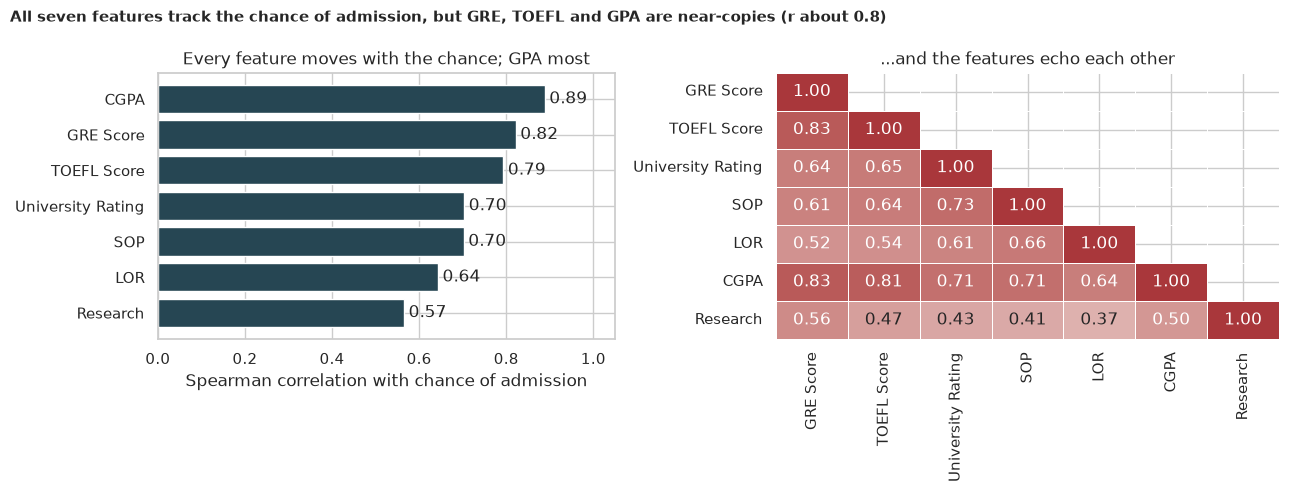

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.1]})
ordered = spearman.iloc[::-1]
axes[0].barh(ordered.index, ordered["rho"], color=NAVY)
for i, value in enumerate(ordered["rho"]):
    axes[0].text(value + 0.01, i, f"{value:.2f}", va="center")
axes[0].set_xlim(0, 1.05)
axes[0].set_xlabel("Spearman correlation with chance of admission")
axes[0].set_title("Every feature moves with the chance; GPA most")

corr = X.corr()
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(
    corr,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    cbar=False,
    ax=axes[1],
)
axes[1].set_title("...and the features echo each other")
fig.suptitle(
    "All seven features track the chance of admission, but GRE, TOEFL and GPA are "
    "near-copies (r about 0.8)",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_feature_correlations.png", dpi=150)
plt.show()

**How to read this.**

- **All 7 features are significantly linked to the chance of admission** (Holm p < 1e-40), and all links are strong: `CGPA` (ρ ≈ **+0.89**), `GRE` (+0.82), `TOEFL` (+0.79), `University Rating` and `SOP` (+0.70), `LOR` (+0.64), `Research` (+0.57).
- **But they echo each other**: `GRE`, `TOEFL` and `CGPA` correlate with each other at about **0.8 to 0.83**, and every feature correlates positively with every other (the heat-map). The VIFs are **moderate**: `CGPA` 4.8, `GRE` 4.5, `TOEFL` 3.9, all below the dangerous 10 but high enough that the individual credit is shared out.
- **That is exactly why marginal and adjusted answers differ.** On its own, `SOP` has ρ ≈ +0.70 (a strong link) but in the adjusted regression it contributes nothing (+0.002). `SOP` correlates with the stronger students, so it *looks* predictive without adding any information beyond what GPA, GRE and the rest already provide.

## 7. H3: do University Rating and SOP add anything?

*What:* the adjusted regression suggested `University Rating` and `SOP` add nothing once the other five features are known. We test that **together** with a **partial F-test** between two **nested** models: the full model (all seven features) and a reduced model (five features, without those two). **H₀:** both coefficients are 0, i.e. the reduced model is just as good.

In [10]:
def nested_f_test(
    features: pd.DataFrame, target: pd.Series, dropped: list[str]
) -> dict[str, float]:
    """Partial F-test: does adding the ``dropped`` features improve on a reduced model?

    Args:
        features: Full feature table.
        target: Chance of admission.
        dropped: Features omitted from the reduced model.

    Returns:
        F statistic, p-value, degrees of freedom and the R-squared of both models.
    """
    full = sm.OLS(target, sm.add_constant(features)).fit()
    reduced = sm.OLS(target, sm.add_constant(features.drop(columns=dropped))).fit()
    f_stat, p_value, df_diff = full.compare_f_test(reduced)
    return {
        "F": f_stat,
        "p": p_value,
        "df": df_diff,
        "R2 full": full.rsquared,
        "R2 reduced": reduced.rsquared,
    }


test = nested_f_test(X, y, ["University Rating", "SOP"])
print(
    f"Partial F-test: F({test['df']:.0f}, {len(y) - X.shape[1] - 1}) = {test['F']:.2f}, "
    f"p = {test['p']:.3f}"
)
print(
    f"R-squared: full model {test['R2 full']:.4f}, without University Rating and SOP "
    f"{test['R2 reduced']:.4f}"
)

Partial F-test: F(2, 492) = 1.71, p = 0.181
R-squared: full model 0.8219, without University Rating and SOP 0.8207


**How to read this.** The partial F-test gives **F(2, 492) ≈ 1.7 and p ≈ 0.18**. **We fail to reject H₀:** dropping `University Rating` and `SOP` together costs only about 0.1 percentage points of R² (0.8219 vs 0.8207), which is not distinguishable from noise. Given the other five features, **the university rating and the SOP score add no detectable information.** (Careful with the usual caveat: "fail to reject" means this sample can't see a contribution, not that none exists. With 500 applicants a small one could be hiding.)

## 8. H4: a leak-free model ladder

*What:* the tests tell us what is *linked*. Now the prediction question: **how well can a model predict the chance of admission for a new applicant, and do fancier models help?** We build a ladder:

1. **Mean baseline:** always predict the average chance. The bar to beat.
2. **Linear: CGPA only**, then **CGPA + GRE**, then **all seven features**.
3. **Linear on the logit scale:** the chance is stuck between 0 and 1, so we fit the line to `logit(chance)` and convert back (a standard fix for bounded targets).
4. **Random forest** and **gradient boosting**, flexible tree-based models.

**How we avoid cheating (data leakage).** Scaling inside a `Pipeline` means the scaler is fitted on the training applicants only, in every fold. The legacy notebook used **one** random 75/25 split and a single seed, so its score could be lucky or unlucky; we use **repeated 5-fold cross-validation** (50 train/test splits) instead.

**How we score.** **MAE (mean absolute error)** is the typical miss in probability points (0.04 means 4 percentage points); **RMSE** punishes large misses more; **R²** is the share of variation explained. We use the **Nadeau-Bengio correction** for confidence intervals: the 50 scores aren't independent because the splits reuse mostly the same applicants, much like several judges reading the same pages of a report, so a plain interval would be too narrow.

In [11]:
def build_models() -> dict[str, object]:
    """Builds the model ladder with scaling inside each pipeline (no leakage).

    Returns:
        Model name mapped to an unfitted estimator.
    """

    def linear(columns: list[str] | None) -> Pipeline:
        scaler = (
            StandardScaler()
            if columns is None
            else ColumnTransformer([("keep", StandardScaler(), columns)])
        )
        return make_pipeline(scaler, LinearRegression())

    return {
        "Mean baseline": DummyRegressor(),
        "Linear: CGPA only": linear(["CGPA"]),
        "Linear: CGPA + GRE": linear(["CGPA", "GRE Score"]),
        "Linear: all 7 features": linear(None),
        "Linear on logit scale": TransformedTargetRegressor(
            linear(None), func=lambda v: logit(np.clip(v, 1e-3, 1 - 1e-3)), inverse_func=expit
        ),
        "Random forest": RandomForestRegressor(
            300, min_samples_leaf=3, random_state=SEED, n_jobs=-1
        ),
        "Gradient boosting": HistGradientBoostingRegressor(
            max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED
        ),
    }


def corrected_ci(scores: np.ndarray, n_train: int, n_test: int) -> tuple[float, float, float]:
    """95% CI for a mean CV score using the Nadeau-Bengio variance correction.

    Args:
        scores: Per-split scores.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        Mean, CI lower bound, CI upper bound.
    """
    k = len(scores)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(scores, ddof=1))
    half = stats.t.ppf(0.975, k - 1) * se
    return float(scores.mean()), float(scores.mean() - half), float(scores.mean() + half)


def corrected_paired_p(diff: np.ndarray, n_train: int, n_test: int) -> float:
    """Two-sided p-value for "do two models differ?" on identical splits.

    Args:
        diff: Per-split score differences between two models.
        n_train: Training rows per split.
        n_test: Test rows per split.

    Returns:
        p-value from the corrected resampled t-test.
    """
    k = len(diff)
    se = np.sqrt((1 / k + n_test / n_train) * np.var(diff, ddof=1))
    return float(2 * stats.t.sf(abs(diff.mean() / se), k - 1))


cv = RepeatedKFold(n_splits=CV_SPLITS, n_repeats=CV_REPEATS, random_state=SEED)
n_test = len(X) // CV_SPLITS
n_train = len(X) - n_test
scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error", "r2": "r2"}

mae_scores, rows = {}, {}
for name, model in build_models().items():
    res = cross_validate(model, X, y, cv=cv, scoring=scoring)
    mae_scores[name] = -res["test_mae"]
    mean, lo, hi = corrected_ci(mae_scores[name], n_train, n_test)
    rows[name] = {
        "MAE": mean,
        "CI low": lo,
        "CI high": hi,
        "RMSE": -res["test_rmse"].mean(),
        "R2": res["test_r2"].mean(),
    }
results = pd.DataFrame(rows).T
results.round(4)

,MAE,CI low,CI high,RMSE,R2
Mean baseline,0.1142,0.1051,0.1233,0.1411,-0.0146
Linear: CGPA only,0.0486,0.0442,0.0531,0.0664,0.7725
Linear: CGPA + GRE,0.0457,0.0416,0.0499,0.0633,0.7933
Linear: all 7 features,0.0434,0.0390,0.0479,0.0603,0.8128
Linear on logit scale,0.0476,0.0428,0.0523,0.0661,0.7740
Random forest,0.0457,0.0410,0.0503,0.0645,0.7855
Gradient boosting,0.0456,0.0413,0.0500,0.0647,0.7849


**How to read this.** (MAE: lower is better, in probability points; R²: higher is better.)

- **Mean baseline:** MAE ≈ **0.114** (11.4 points) and R² ≈ 0: no skill.
- **CGPA alone** already gets MAE ≈ **0.049** and R² ≈ **0.77**: one number explains three-quarters of the variation.
- **All seven features (plain linear regression): MAE ≈ 0.043 (4.3 points), R² ≈ 0.81**, the best of the ladder.
- **The logit-scale model is *worse* (0.048), and the forest (0.046) and boosting (0.046) don't beat the simple linear model.** The "theoretically better" bounded-target fix didn't help, and the flexible models gain nothing because the underlying relationship is close to a straight line.

Now the paired tests, to see whether those gaps are real or just noise between splits.

In [12]:
reference = "Linear: all 7 features"
comparison = {}
for name, scores in mae_scores.items():
    if name == reference:
        continue
    diff = scores - mae_scores[reference]
    comparison[name] = {
        "MAE minus linear-all": diff.mean(),
        "paired p": corrected_paired_p(diff, n_train, n_test),
    }
pd.DataFrame(comparison).T.style.format({"MAE minus linear-all": "{:+.4f}", "paired p": "{:.4f}"})

,MAE minus linear-all,paired p
Mean baseline,+0.0708,0.0000
Linear: CGPA only,+0.0052,0.0012
Linear: CGPA + GRE,+0.0023,0.0145
Linear on logit scale,+0.0041,0.0026
Random forest,+0.0022,0.0637
Gradient boosting,+0.0022,0.0564


**How to read this.** A positive number means *worse than the all-features linear model*.

- **Mean baseline: clearly worse** (p ≈ 0).
- **CGPA only: worse by about 0.005 (p ≈ 0.001), and CGPA + GRE by 0.002 (p ≈ 0.015).** The extra features add a small but real improvement. So one GPA number is nearly enough, but not quite.
- **Logit-scale model: worse by about 0.004 (p ≈ 0.003).**
- **Random forest and boosting: worse by about 0.002, not significant (p ≈ 0.06).** We **fail to reject H₀**: the flexible models are not distinguishable from linear regression, and the point estimates are slightly worse.

So **a plain linear regression is a hard baseline to beat here**, and every extra bit of model complexity either did nothing or hurt.

### Picture the comparison

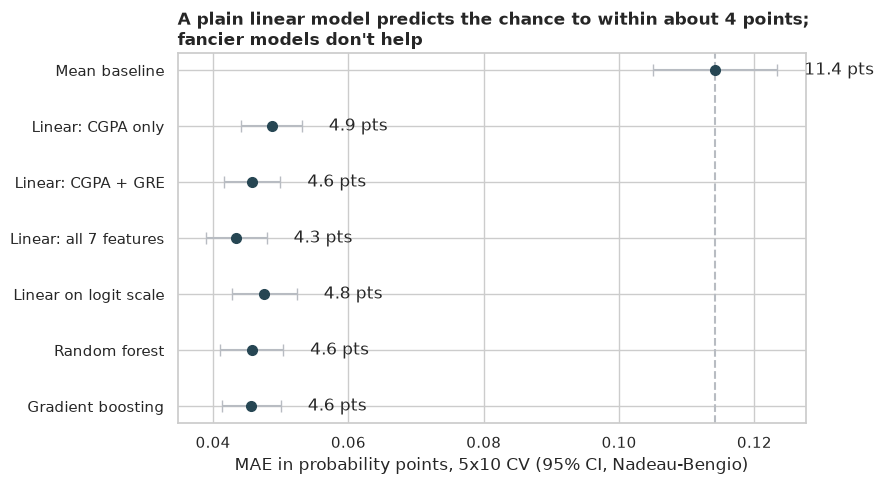

In [13]:
fig, ax = plt.subplots(figsize=(9, 5))
names = list(results.index)
ypos = np.arange(len(names))
ax.errorbar(
    results["MAE"],
    ypos,
    xerr=[results["MAE"] - results["CI low"], results["CI high"] - results["MAE"]],
    fmt="o",
    color=NAVY,
    ecolor=GREY,
    capsize=4,
    markersize=7,
)
for i, value in enumerate(results["MAE"]):
    ax.text(results["CI high"].iloc[i] + 0.004, i, f"{value * 100:.1f} pts", va="center")
ax.axvline(results.loc["Mean baseline", "MAE"], ls="--", color=GREY)
ax.set_yticks(ypos, names)
ax.invert_yaxis()
ax.set_xlabel(f"MAE in probability points, {CV_SPLITS}x{CV_REPEATS} CV (95% CI, Nadeau-Bengio)")
ax.set_title(
    "A plain linear model predicts the chance to within about 4 points;\nfancier models don't help",
    loc="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_model_comparison.png", dpi=150)
plt.show()

**How to read this.** Each dot is a model's typical miss with its 95% interval; the dashed line is the "always guess the average" baseline. From the CGPA-only model down, the intervals overlap heavily: the visual version of the paired tests.

### Where does the linear model miss?

*What:* predictions for every applicant from a model that never saw that applicant (`cross_val_predict`), plotted against the truth. *Why:* a good average score can hide patterns in the errors. We particularly want to know whether the model is equally accurate for low-chance and high-chance applicants, since the chance can't go above 1. **H₀:** the size of the miss is unrelated to the predicted value (Spearman ρ between the predicted value and the absolute miss = 0).

In [14]:
oof = pd.Series(
    cross_val_predict(
        build_models()["Linear: all 7 features"],
        X,
        y,
        cv=KFold(CV_SPLITS, shuffle=True, random_state=SEED),
    ),
    index=y.index,
)
miss = y - oof
spread = stats.spearmanr(oof, miss.abs())
bins = pd.cut(oof, [0, 0.6, 0.75, 0.9, 1.0], labels=["< 0.60", "0.60-0.75", "0.75-0.90", "> 0.90"])
by_bin = miss.abs().groupby(bins, observed=True).agg(["size", "mean"])
by_bin.columns = ["applicants", "mean absolute miss"]
print(
    f"Spearman correlation between predicted chance and size of miss: "
    f"rho = {spread.statistic:+.2f}, p = {fmt_p(spread.pvalue)}"
)
print(f"Out-of-fold MAE {miss.abs().mean():.4f}; skewness of the misses {stats.skew(miss):+.2f}")
by_bin.style.format({"applicants": "{:.0f}", "mean absolute miss": "{:.3f}"})

Spearman correlation between predicted chance and size of miss: rho = -0.33, p = 3.0e-14
Out-of-fold MAE 0.0437; skewness of the misses -1.13


,applicants,mean absolute miss
< 0.60,91,0.059
0.60-0.75,205,0.051
0.75-0.90,152,0.034
> 0.90,52,0.016


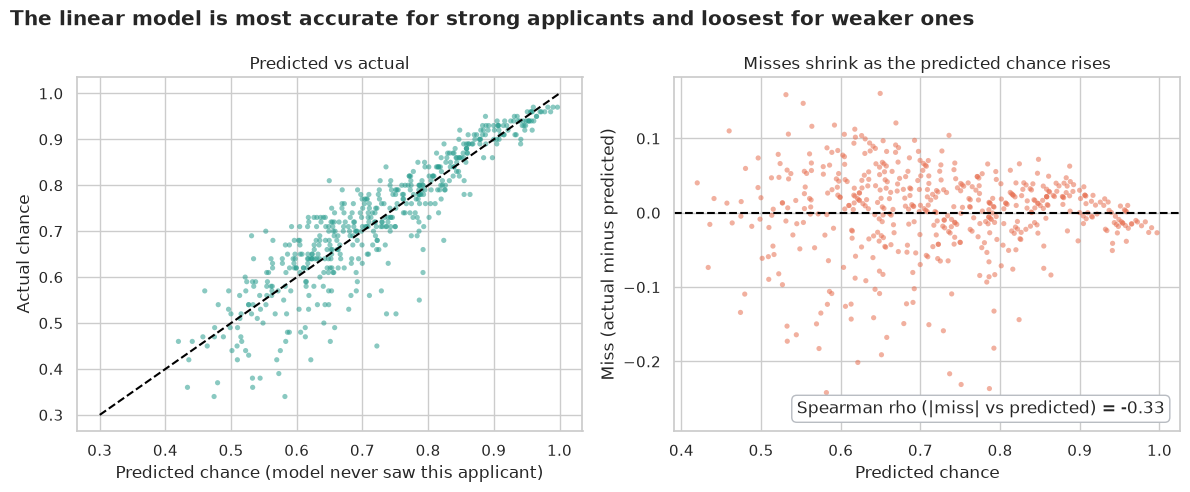

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(oof, y, s=14, alpha=0.55, color=TEAL, edgecolor="none")
axes[0].plot([0.3, 1], [0.3, 1], color="black", ls="--")
axes[0].set_xlabel("Predicted chance (model never saw this applicant)")
axes[0].set_ylabel("Actual chance")
axes[0].set_title("Predicted vs actual")
axes[1].scatter(oof, miss, s=14, alpha=0.55, color=ORANGE, edgecolor="none")
axes[1].axhline(0, color="black", ls="--")
axes[1].set_xlabel("Predicted chance")
axes[1].set_ylabel("Miss (actual minus predicted)")
axes[1].text(
    0.97,
    0.05,
    f"Spearman rho (|miss| vs predicted) = {spread.statistic:+.2f}",
    transform=axes[1].transAxes,
    ha="right",
    bbox={"boxstyle": "round", "fc": "white", "ec": GREY},
)
axes[1].set_title("Misses shrink as the predicted chance rises")
fig.suptitle(
    "The linear model is most accurate for strong applicants and loosest for weaker ones",
    x=0.01,
    ha="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "05_residuals.png", dpi=150)
plt.show()

**How to read this.** The misses are **not equally sized across the range**:

- Applicants the model predicts below 0.60 miss by about **0.059** on average (5.9 points, 91 applicants), those at 0.60 to 0.75 by **0.051**, those at 0.75 to 0.90 by **0.034**, and those above 0.90 by only **0.016** (1.6 points, 52 applicants).
- The Spearman correlation between the predicted chance and the size of the miss is **ρ ≈ −0.33 (p ≈ 3e-14)**, so **we reject H₀**: the model is *much* more accurate for strong applicants than for weak ones. This is the "ceiling effect": near 1.0 there is simply less room to be wrong, and the chance values bunch up.
- The misses are also **lopsided** (skewness about −1.1): the model tends to over-predict a few weaker applicants by a lot (large negative misses) rather than miss in both directions equally. This is why we used robust (HC3) standard errors for the inference in section 5.

## 9. H5: which feature is "important"? Two ways to ask

*What:* the legacy notebook ended with a bar chart of a random forest's **impurity-based importance** and declared that CGPA, then GRE and so on, mattered most. That method counts *how often a feature is used to split the data*, measured **on the training data**, and it is known to be unreliable when features echo each other. A better question is: **if I scramble this feature for applicants the model has never seen, how much worse do its predictions get?** That is **permutation importance**, measured on **held-out** data (here: the increase in MAE).

We compare three views: the legacy forest impurity importance, permutation importance for the linear model, and permutation importance for the forest. To keep it honest, the permutation scores are computed on held-out folds only.

In [16]:
def held_out_permutation(model_factory, repeats: int = 2) -> pd.Series:
    """Permutation importance (increase in MAE) averaged over held-out folds.

    Args:
        model_factory: Callable returning a fresh unfitted model.
        repeats: How many times to repeat the 5-fold split.

    Returns:
        Mean MAE increase per feature when that feature is scrambled in the test fold.
    """
    scores = []
    folds = RepeatedKFold(n_splits=CV_SPLITS, n_repeats=repeats, random_state=SEED)
    for train, test in folds.split(X):
        model = model_factory().fit(X.iloc[train], y.iloc[train])
        result = permutation_importance(
            model,
            X.iloc[test],
            y.iloc[test],
            n_repeats=20,
            random_state=SEED,
            scoring="neg_mean_absolute_error",
        )
        scores.append(result.importances_mean)
    return pd.Series(np.mean(scores, axis=0), index=FEATURES)


def linear_factory() -> Pipeline:
    """Fresh scaled linear regression."""
    return make_pipeline(StandardScaler(), LinearRegression())


def forest_factory() -> RandomForestRegressor:
    """Fresh random forest with the notebook's settings."""
    return RandomForestRegressor(300, min_samples_leaf=3, random_state=SEED, n_jobs=-1)


impurity = pd.Series(forest_factory().fit(X, y).feature_importances_, index=FEATURES)
importance = pd.DataFrame(
    {
        "Legacy: forest impurity": impurity / impurity.sum(),
        "Permutation: linear model": held_out_permutation(linear_factory).clip(lower=0),
        "Permutation: forest": held_out_permutation(forest_factory).clip(lower=0),
    }
)
importance = importance / importance.sum()  # each method as a share of 100%
importance = importance.sort_values("Permutation: linear model", ascending=False)
importance.style.format("{:.1%}")

,Legacy: forest impurity,Permutation: linear model,Permutation: forest
CGPA,83.7%,74.7%,88.6%
GRE Score,8.0%,10.0%,6.3%
TOEFL Score,2.9%,6.4%,0.8%
LOR,1.7%,5.0%,1.1%
Research,0.9%,2.9%,0.9%
University Rating,1.1%,0.9%,1.5%
SOP,1.7%,0.0%,0.8%


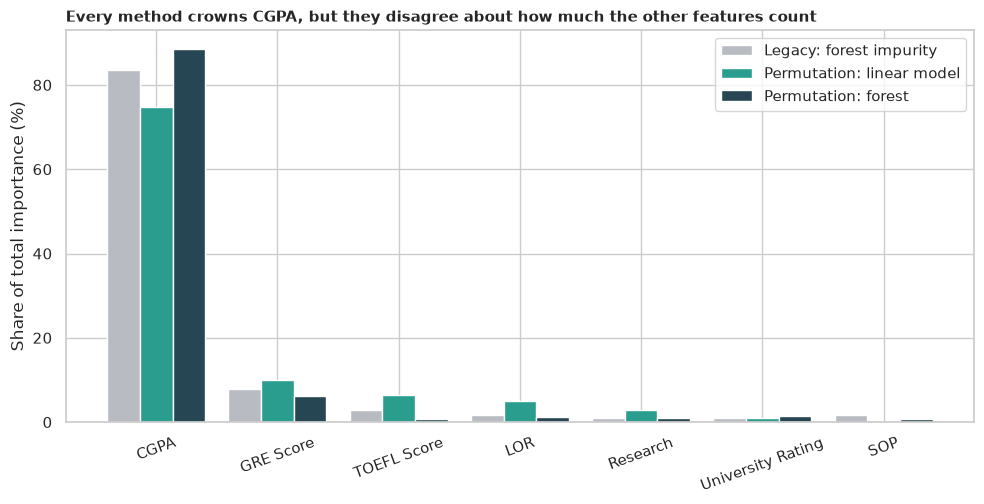

In [17]:
fig, ax = plt.subplots(figsize=(10, 5.2))
width = 0.27
positions = np.arange(len(importance))
for i, (column, color) in enumerate(zip(importance.columns, (GREY, TEAL, NAVY), strict=True)):
    ax.bar(positions + (i - 1) * width, importance[column] * 100, width, label=column, color=color)
ax.set_xticks(positions, importance.index, rotation=20)
ax.set_ylabel("Share of total importance (%)")
ax.legend()
ax.set_title(
    "Every method crowns CGPA, but they disagree about how much the other features count",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_importance_methods.png", dpi=150)
plt.show()

**How to read this.** Each bar is a feature's **share of the total importance** under that method (so the three bar groups are comparable, whatever the units).

- **All three methods agree on the winner:** `CGPA` takes by far the biggest share (about **75% to 89%**).
- **They disagree on the rest.** The legacy impurity importance (grey) gives `GRE` about 8%, `TOEFL` about 3% and the small features a few percent each, including `SOP` and `LOR` at about 2%. Permutation importance for the *linear* model (teal) spreads credit differently: more to `GRE`, `TOEFL` and `LOR`, and almost nothing to `SOP` and `University Rating`, which matches the F-test. Permutation for the *forest* (navy) puts nearly everything on `CGPA` and `GRE`.
- **Why they differ:** when features echo each other, importance depends on the **method and the model**. Scrambling `GRE` hurts a lot less once `TOEFL` and `CGPA` can stand in for it, and a forest happily uses whichever correlated feature it splits on first. So *"which feature is more important after CGPA"* has no single answer here; only the top spot is robust.

## 10. 🎯 Takeaways

1. **GPA is the main driver.** `CGPA` alone has ρ ≈ +0.89 with the chance and gives R² ≈ 0.77 on its own; every importance method names it the top feature.
2. **Research experience looks big but mostly isn't.** The raw gap is +15.5 points (Cliff's δ ≈ +0.66), but research students are also stronger on GPA and test scores. Holding GPA fixed cuts it to **+3.9 points** (about 75% of the gap explained), and holding all the other scores fixed cuts it to **+2.4 points** (CI +0.9 to +4.0): about **84% of the raw gap disappears**.
3. **Echoing features make credit hard to assign.** `GRE`, `TOEFL` and `CGPA` correlate at about 0.8; `SOP` and `University Rating` look predictive alone (ρ ≈ +0.70) but add nothing detectable once the others are known (partial F-test p ≈ 0.18).
4. **A plain linear regression is hard to beat.** MAE ≈ 4.3 points (R² ≈ 0.81); the logit link, a random forest and gradient boosting did no better, and some did slightly worse.
5. **Importance depends on the method.** Only the top spot (`CGPA`) is robust; the ranking of the rest changes with the model and the method.

## 11. ⚠️ Limitations and edge cases

- **The target is not a real admission decision.** "Chance of Admit" is an estimated number built for a teaching dataset, so models here learn that number's recipe, not what real admissions committees do. Please don't read these results as advice about getting into a real programme.
- **Association, not cause.** Even the adjusted research effect is an association. Unmeasured things (the quality of the research, the applicant's field) could be at work.
- **Small data.** 500 applicants, with 7 features and a bounded target; some effects (SOP, University Rating) could be small but real and just invisible here.
- **Ceiling effects.** The chance can't exceed 1, and the model's errors are larger for lower-chance applicants than for high-chance ones (see how the spread of residuals changes with the predicted value). Robust standard errors handle the inference, but prediction errors are not uniform.
- **Ordinal scores treated as numbers.** SOP, LOR and University Rating are 1 to 5 ratings (in half steps), used here as if they were measured quantities.
- **Tuning scope.** The forest and boosting use sensible defaults without a full hyper-parameter search; a heavily tuned model might close some of the small gap.
- **Manual download.** The data needs a Kaggle login, so this notebook cannot fetch it automatically.

---
*Run `uv run jupyter nbconvert --to html --execute ML/graduate-admission/graduate_admission.ipynb --output-dir docs --output ml-graduate-admission` to rebuild the web version (`docs/ml-graduate-admission.html`).*